# Laboratorio Dry Bean - Sprint 2: modelado y evaluación

**Proyecto:** Clasificación de variedades de frijol seco (Dry Bean Dataset, UCI 602)
**Equipo:** Jacobo Unzueta y Rommel Prieto - Maestría en IA y Ciencia de Datos, Universidad Autónoma de Occidente
**Metodologías:** CRISP-DM · TDSP · Scrum ML
**Sprint 2:** PB-03 (baseline), PB-04 (Random Forest) y PB-05 (comparación de métricas)

## Objetivo del sprint

Entrenar un modelo baseline y un modelo alternativo, compararlos con métricas
adecuadas al desbalance de clases y decidir cuál pasa a despliegue.

**Requisito:** haber ejecutado antes `python -m src.sprint1` (genera `data/processed/`).


## 0. Configuración e importaciones

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import json
import pandas as pd
from IPython.display import Image, display

from src import config, models, prepare
from src.eda import dataframe_to_markdown

pd.set_option("display.width", 120)
print("Raíz del proyecto:", config.PROJECT_ROOT)
print("Semilla:", config.RANDOM_STATE)

Raíz del proyecto: C:\Users\Jacobo\Documents\GestionProyectosIA\laboratorio_drybean_ml
Semilla: 42


## 1. Cargar los conjuntos procesados del Sprint 1

Usamos exactamente el mismo split estratificado, así la comparación entre modelos
es justa y reproducible.

In [2]:
X_train, X_test, y_train, y_test = prepare.load_processed_data()
print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Clases: {sorted(y_train.unique())}")

Train: (10834, 16) | Test: (2709, 16)
Clases: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']


## 2. Baseline: regresión logística (PB-03)

`StandardScaler` + `LogisticRegression(max_iter=1000)`: un primer modelo simple que
sirve de punto de comparación. El escalamiento vive dentro del pipeline, por lo
que se ajusta solo con train.

In [3]:
baseline, baseline_seconds = models.train_model(
    models.build_baseline_pipeline(), X_train, y_train
)
baseline_result = models.evaluate_model(
    baseline, X_test, y_test, models.BASELINE_NAME, baseline_seconds
)

print("Pipeline:", baseline)
print(f"Tiempo de entrenamiento: {baseline_seconds:.2f}s")
print(f"Accuracy: {baseline_result['metrics']['accuracy']:.4f}")
print(f"F1 macro: {baseline_result['metrics']['f1_macro']:.4f}")
print()
from sklearn.metrics import classification_report
print(classification_report(y_test, baseline_result["y_pred"], zero_division=0))

Pipeline: Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])
Tiempo de entrenamiento: 0.11s
Accuracy: 0.9195
F1 macro: 0.9306

              precision    recall  f1-score   support

    BARBUNYA       0.93      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.91      0.94      0.93       326
    DERMASON       0.93      0.91      0.92       709
       HOROZ       0.96      0.94      0.95       372
       SEKER       0.93      0.94      0.94       406
        SIRA       0.86      0.89      0.87       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



**Pregunta del laboratorio:** ¿por qué F1 macro puede ser más informativo que
accuracy cuando las clases no están perfectamente balanceadas?

**Respuesta:** accuracy promedia todos los aciertos por igual y con 7 clases
desbalanceadas (6,79:1) una clase mayoritaria bien predicha puede esconder fallos
en `BOMBAY` o `BARBUNYA`. F1 macro promedia el F1 de cada clase con el mismo peso,
así que penaliza a un modelo que abandona las clases minoritarias.

## 3. Modelo alternativo: Random Forest (PB-04)

200 árboles con `class_weight="balanced"` para compensar el desbalance detectado en
el Sprint 1. Los árboles no necesitan escalamiento: se entrena con las variables
originales.

In [4]:
forest, forest_seconds = models.train_model(
    models.build_forest_model(), X_train, y_train
)
forest_result = models.evaluate_model(
    forest, X_test, y_test, models.FOREST_NAME, forest_seconds
)

print(f"Tiempo de entrenamiento: {forest_seconds:.2f}s")
print(f"Accuracy: {forest_result['metrics']['accuracy']:.4f}")
print(f"F1 macro: {forest_result['metrics']['f1_macro']:.4f}")
print()
print(classification_report(y_test, forest_result["y_pred"], zero_division=0))

Tiempo de entrenamiento: 0.38s
Accuracy: 0.9195
F1 macro: 0.9310

              precision    recall  f1-score   support

    BARBUNYA       0.92      0.90      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.94      0.93       326
    DERMASON       0.92      0.91      0.91       709
       HOROZ       0.96      0.95      0.96       372
       SEKER       0.92      0.96      0.94       406
        SIRA       0.87      0.87      0.87       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



## 4. Comparación de modelos (PB-05)

Misma métrica, mismo conjunto de prueba: la tabla es la evidencia para la
decisión CRISP-DM.

In [5]:
results = {"baseline": baseline_result, "forest": forest_result}
comparison = models.build_comparison_table(results)
print(dataframe_to_markdown(comparison.reset_index()))

|  | modelo | accuracy | f1_macro | f1_weighted | balanced_accuracy | precision_macro | recall_macro | train_seconds |
|---|---|---|---|---|---|---|---|---|
| 0 | baseline | 0.919 | 0.931 | 0.920 | 0.930 | 0.931 | 0.930 | 0.109 |
| 1 | forest | 0.919 | 0.931 | 0.919 | 0.931 | 0.931 | 0.931 | 0.381 |


Coincidencia entre modelos: 96.05% de las predicciones


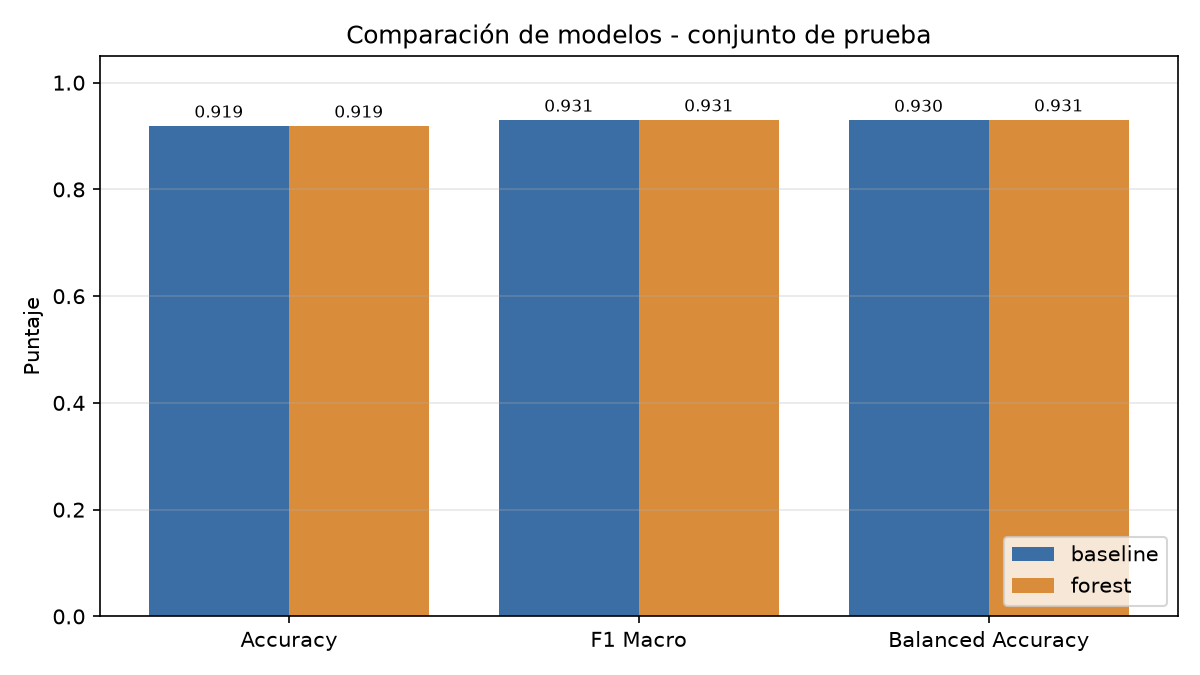

In [6]:
agreement = (baseline_result["y_pred"] == forest_result["y_pred"]).mean()
print(f"Coincidencia entre modelos: {agreement:.2%} de las predicciones")

for figura in ["comparacion_modelos.png"]:
    display(Image(filename=str(config.SPRINT2_FIGURES_DIR / figura)))

## 5. Matriz de confusión

La matriz muestra **dónde** falla el modelo, no solo cuánto.

confusion_forest.png


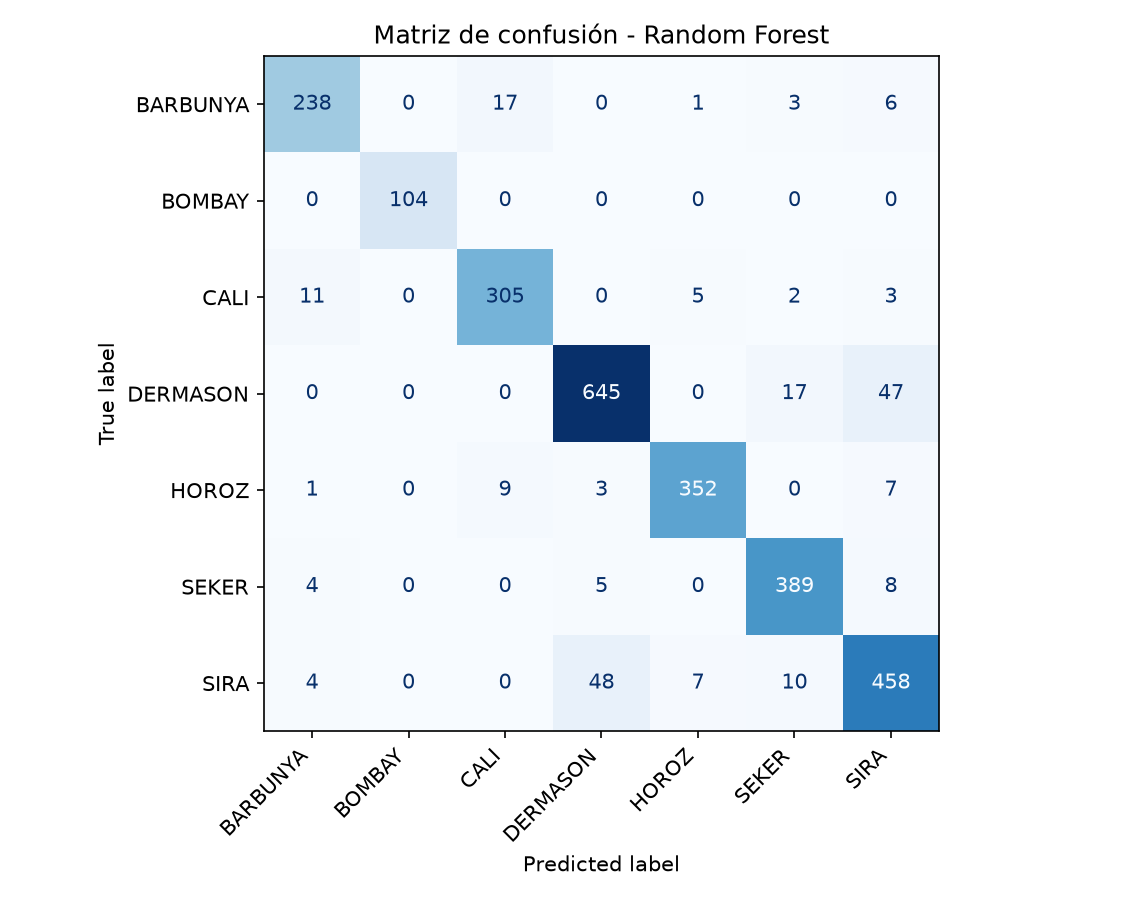

confusion_baseline.png


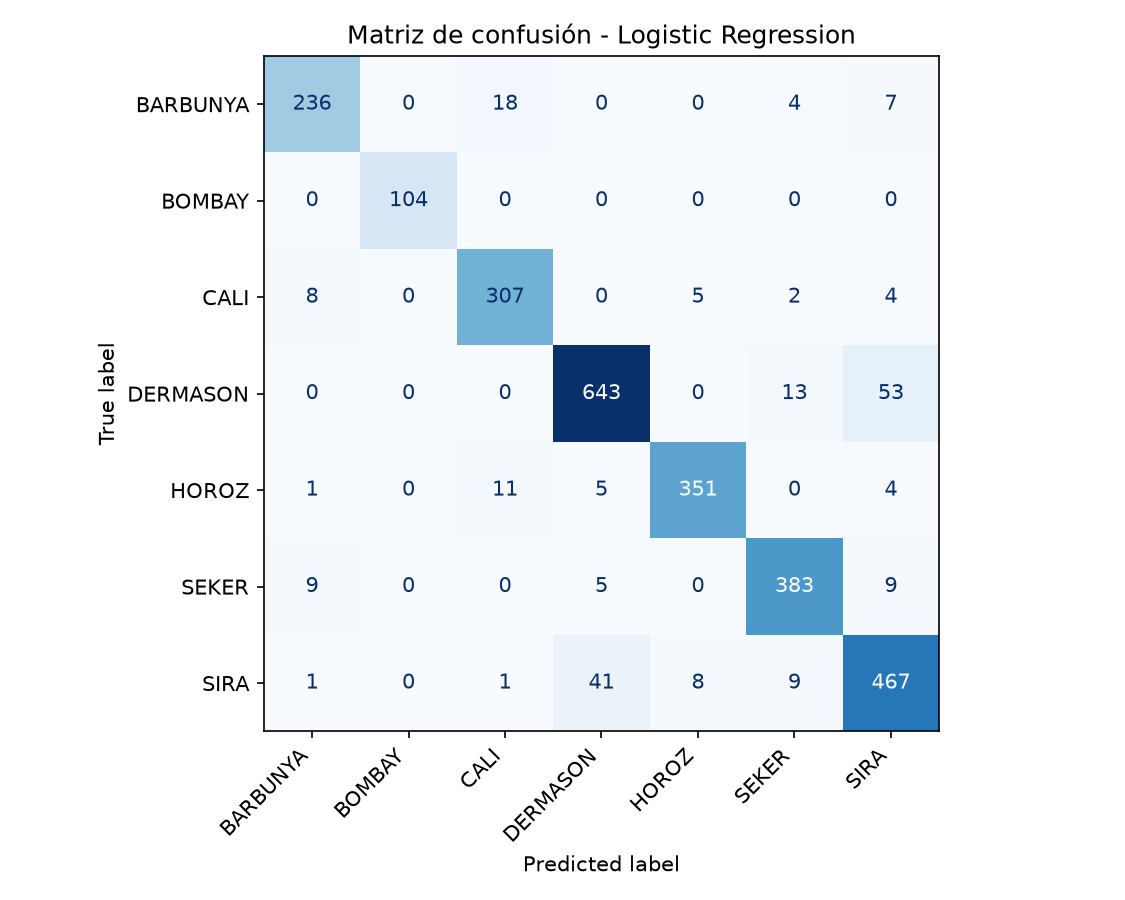

In [7]:
for figura in ["confusion_forest.png", "confusion_baseline.png"]:
    print(figura)
    display(Image(filename=str(config.SPRINT2_FIGURES_DIR / figura)))

In [8]:
from src import evaluate

for par in evaluate.top_confusions(forest_result, n=5):
    print(
        f"{par['real']:>9} -> {par['predicho']:<9} "
        f"{par['casos']:>4} casos ({par['tasa']:.1%} de la clase real)"
    )

     SIRA -> DERMASON    48 casos (9.1% de la clase real)
 DERMASON -> SIRA        47 casos (6.6% de la clase real)
 BARBUNYA -> CALI        17 casos (6.4% de la clase real)
 DERMASON -> SEKER       17 casos (2.4% de la clase real)
     CALI -> BARBUNYA    11 casos (3.4% de la clase real)


**Pregunta del laboratorio:** ¿qué clases se confunden más entre sí?

`SIRA` y `DERMASON` se confunden en ambos sentidos (son variedades de tamaño y
forma parecidos). `BOMBAY`, la más pequeña y minoritaria, se clasifica sin errores:
sus medidas geométricas son claramente distintas.

## 6. Importancia de variables

Explica qué usó el bosque para separar las clases. **No prueba causalidad.**

| # | variable | importancia |
|---|---|---|
| 1 | Perimeter | 0.109 |
| 2 | ShapeFactor1 | 0.102 |
| 3 | Compactness | 0.095 |
| 4 | ShapeFactor3 | 0.094 |
| 5 | MinorAxisLength | 0.093 |
| 6 | EquivDiameter | 0.067 |
| 7 | Roundness | 0.062 |
| 8 | AspectRatio | 0.060 |
| 9 | Eccentricity | 0.059 |
| 10 | Area | 0.058 |


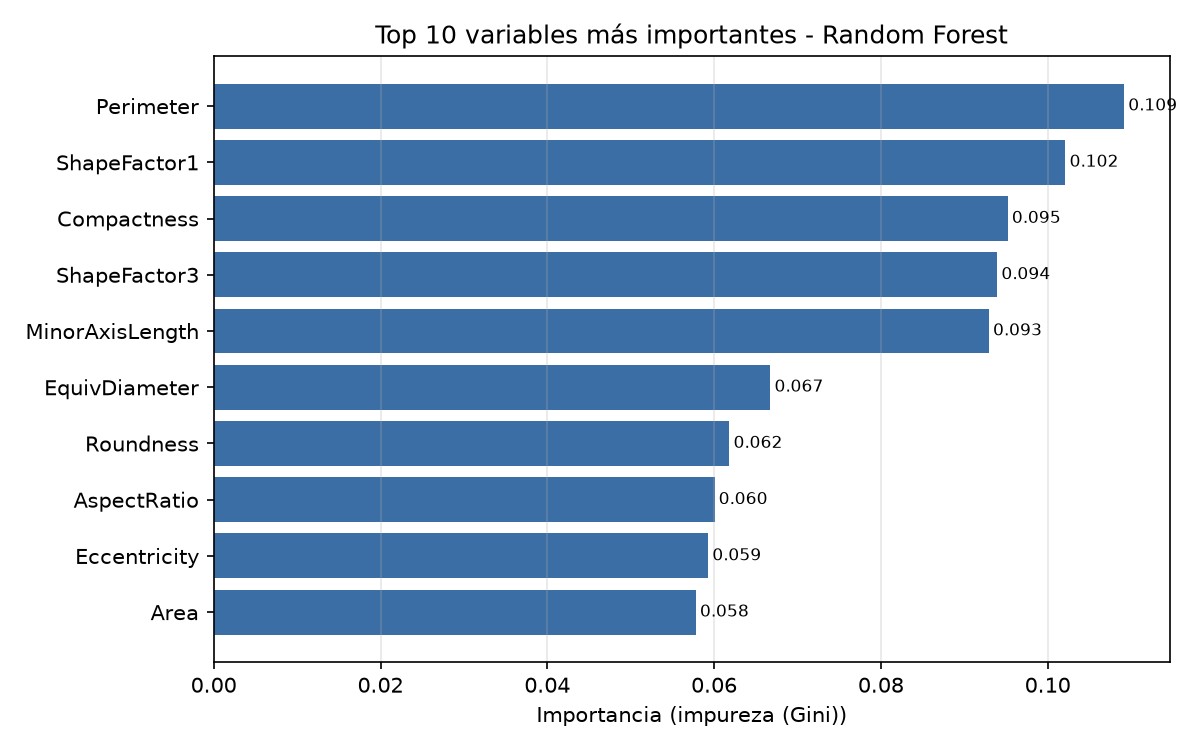

In [9]:
importance = models.feature_importance(forest, list(X_train.columns))
top10 = importance.head(10).copy()
top10.index = range(1, len(top10) + 1)
top10.index.name = "#"
print(dataframe_to_markdown(top10))

display(Image(filename=str(config.SPRINT2_FIGURES_DIR / "importancia_variables.png")))

## 7. Decisión CRISP-DM: qué modelo pasa a despliegue

Criterio del laboratorio: priorizar `f1_macro`, revisar errores por clase y, si el
desempeño es equivalente, preferir el modelo más simple.

In [10]:
selection = models.select_best_model(comparison)
print("Ranking F1 macro:", selection["ranking"])
print("Modelo seleccionado:", selection["selected"])
print("Justificación:", selection["rationale"])

Ranking F1 macro: {'forest': 0.931, 'baseline': 0.9306}
Modelo seleccionado: baseline
Justificación: La diferencia de F1 macro entre forest y baseline es 0.0004 (< 0.005), por lo que se prefiere el modelo mas simple y rapido: baseline.


In [11]:
metadata = json.loads(
    config.FINAL_MODEL_PATH.with_suffix(".metadata.json").read_text(encoding="utf-8")
)
print("Artefacto:", config.FINAL_MODEL_PATH.name)
print(json.dumps(
    {k: metadata[k] for k in ["selected_model", "metrics", "train_rows", "test_rows", "sklearn_version"]},
    indent=2,
    ensure_ascii=False,
))

Artefacto: modelo_final_drybean.joblib
{
  "selected_model": "baseline",
  "metrics": {
    "accuracy": 0.9195275009228497,
    "f1_macro": 0.930983998605991
  },
  "train_rows": 10834,
  "test_rows": 2709,
  "sklearn_version": "1.9.1"
}


## 8. Conclusiones del Sprint 2

1. Ambos modelos aciertan ~91,95% del conjunto de prueba: las variables
   geométricas son muy informativas.
2. Los modelos coinciden en ~96% de las predicciones; el F1 macro desempata y el
   costo computacional favorece al baseline.
3. `SIRA` ↔ `DERMASON` es la confusión dominante; `BOMBAY` se separa sin errores.
4. El modelo seleccionado queda guardado en `outputs/models/` con metadatos de
   trazabilidad (versión de scikit-learn, métricas, features y clases).
5. El siguiente paso (Sprint 3) es el despliegue: cargar el `.joblib`, predecir
   desde una función reutilizable y documentar el proyecto completo.
